**Introducción a la Ciencia de Datos 2026**
Posgrado en Ciencias de la Computación - CICESE
Dr. Irvin Hussein López Nava

## ICD - 18: Boosting

Sesión 18 del curso. Diapositivas: [icd-18-boosting.pdf](https://github.com/husseinlopez/icd2026/blob/main/clases/icd-18-boosting.pdf)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/husseinlopez/icd2026/blob/main/icd-18-boosting.ipynb)

Ayer combinamos modelos entrenados **en paralelo**: bagging y random forest promedian árboles profundos y bajan su varianza. Hoy el **boosting**: modelos entrenados **en secuencia**, cada uno sobre los errores de los anteriores, que convierten modelos débiles en uno fuerte y bajan el sesgo.

El notebook tiene seis partes. En la primera hacemos AdaBoost a mano con los 14 días y vemos de dónde sale el peso de cada modelo. En la segunda llevamos AdaBoost al vino, con tres clases. En la tercera hacemos a mano la primera ronda de gradient boosting y la comparamos con scikit-learn; en la cuarta, la de XGBoost. En la quinta vemos la tasa de aprendizaje y la parada temprana. En la sexta comparamos las bibliotecas y cerramos la tabla de la unidad 5.

---

### Preparación

Además de las de siempre, hoy usamos tres bibliotecas de gradient boosting: XGBoost, LightGBM y CatBoost. Están en `requirements.txt`; en Colab, si falta alguna, instálala con `!pip install xgboost lightgbm catboost`.

In [1]:
import math
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import xgboost
import lightgbm
import catboost

# staged_predict de AdaBoost pasa los datos a sus árboles sin los nombres de las columnas, y scikit-learn lo avisa
# en cada llamada. Es interno y no cambia los resultados.
warnings.filterwarnings("ignore", message="X does not have valid feature names")

print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("matplotlib  ", matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("xgboost     ", xgboost.__version__)
print("lightgbm    ", lightgbm.__version__)
print("catboost    ", catboost.__version__)

numpy        2.5.3
pandas       3.0.5
matplotlib   3.11.2
scikit-learn 1.9.1
xgboost      3.4.1
lightgbm     4.7.0
catboost     1.2.10


Paleta y estilo de las sesiones anteriores. En las figuras, el naranja marca lo que sale mal o es optimista, y el azul, lo que se recomienda.

In [2]:
AZUL_OSCURO = "#112057"
AZUL = "#7697CD"
AZUL_MEDIO = "#3C51A9"
NARANJA = "#E76A28"
GRIS = "#5B6584"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlecolor": AZUL_OSCURO,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": AZUL_OSCURO,
    "axes.edgecolor": "#C9CFDF",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#E3E6EF",
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "legend.frameon": False,
})

SEMILLA = 42        # fija las particiones y los sorteos para que los resultados se repitan

---

### Los datos

- `weather.nominal.csv` son los 14 días de las sesiones 13 y 14; `weather.prueba.csv`, los 14 días de prueba de la sesión 15.
- `vinos-3clases.csv` es el vino de 3 clases de la sesión 12.

En las tres lecturas, la primera línea funciona tal cual desde la carpeta del repositorio clonado. En Colab, comenta la primera y descomenta la segunda.

In [3]:
nominal = pd.read_csv("datos/weather.nominal.csv")
# nominal = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/weather.nominal.csv")

prueba = pd.read_csv("datos/weather.prueba.csv")
# prueba = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/weather.prueba.csv")

vinos = pd.read_csv("datos/vinos-3clases.csv")
# vinos = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/vinos-3clases.csv")

print(f"Días: {len(nominal)} de entrenamiento y {len(prueba)} de prueba. Vinos: {len(vinos)}.")

Días: 14 de entrenamiento y 14 de prueba. Vinos: 1599.


---

## 1. AdaBoost a mano: los 14 días

### La primera ronda

El algoritmo de las diapositivas 12 y 13, con las clases como $y_i \in \{-1, +1\}$: Sí es $+1$ y No es $-1$. Todos los días empiezan con el mismo peso, $w_i = 1/14$. En cada ronda $t$:

1. Se entrena un modelo débil $h_t$ con los pesos $w$.
2. Su error ponderado $\varepsilon_t$ es la suma de los pesos de los ejemplos que clasifica mal.
3. Su peso en el voto es $\alpha_t = \frac{1}{2}\ln\frac{1-\varepsilon_t}{\varepsilon_t}$.
4. Los pesos se actualizan, $w_i \leftarrow w_i\, e^{-\alpha_t y_i h_t(x_i)} / Z_t$: los mal clasificados se multiplican por $e^{\alpha_t}$, los bien clasificados por $e^{-\alpha_t}$, y $Z_t$ normaliza para que sumen 1.

El clasificador final es $H(x) = \mathrm{signo}\left(\sum_t \alpha_t h_t(x)\right)$.

El modelo débil es un **tocón de varias ramas**: pregunta un solo atributo y, en cada rama, predice la clase con más peso.

In [4]:
ATRIBUTOS = ["Outlook", "Temperature", "Humidity", "Wind"]
ORDEN = ["sunny", "overcast", "rain", "hot", "mild", "cool", "high", "normal", "weak", "strong"]
y_dias = np.where(nominal.Play, 1, -1)


def tocones(w, datos=nominal, y=y_dias):
    # Para cada atributo, el tocón de varias ramas: cada rama predice la clase con más peso.
    salida = {}
    for a in ATRIBUTOS:
        reglas = {}
        for v in sorted(datos[a].unique(), key=ORDEN.index):
            en_rama = (datos[a] == v).to_numpy()
            reglas[v] = 1 if w[en_rama & (y == 1)].sum() >= w[en_rama & (y == -1)].sum() else -1
        pred = datos[a].map(reglas).to_numpy()
        salida[a] = {"reglas": reglas, "pred": pred, "error": w[pred != y].sum()}
    return salida


def tocon(w):
    # El tocón con menor error ponderado; en un empate, el del primer atributo de la lista.
    todos = tocones(w)
    a = min(todos, key=lambda k: (round(todos[k]["error"], 12), ATRIBUTOS.index(k)))
    return a, todos[a]


def texto(reglas):
    return ", ".join(f"{v} → {'Sí' if c > 0 else 'No'}" for v, c in reglas.items())


w = np.full(14, 1 / 14)
print("Errores de cada tocón en la ronda 1:", {a: f"{t['error'] * 14:.0f}/14" for a, t in tocones(w).items()})
a, t = tocon(w)
eps = t["error"]
alfa = 0.5 * math.log((1 - eps) / eps)
print(f"Ronda 1: {a} ({texto(t['reglas'])}); falla los días {nominal.Day[t['pred'] != y_dias].tolist()}")
print(f"ε = 4/14 = {eps:.3f};  α = ½ ln({1 - eps:.3f}/{eps:.3f}) = ½ ln {(1 - eps) / eps:.1f} = {alfa:.3f}")
mal, bien = w[0] * math.exp(alfa), w[0] * math.exp(-alfa)
print(f"Mal clasificados: (1/14) e^{alfa:.3f} = {mal:.4f};  bien clasificados: (1/14) e^-{alfa:.3f} = {bien:.4f}")
nuevo = w * np.exp(-alfa * y_dias * t["pred"])
Z = nuevo.sum()
print(f"Z = 4({mal:.4f}) + 10({bien:.4f}) = {Z:.4f};  con la fórmula, 2√(ε(1 − ε)) = {2 * math.sqrt(eps * (1 - eps)):.4f}")
pesos = pd.DataFrame({"antes": w, "después": nuevo / Z}, index=nominal.Day.rename("día")).T
pesos.round(3)

Errores de cada tocón en la ronda 1: {'Outlook': '4/14', 'Temperature': '5/14', 'Humidity': '4/14', 'Wind': '5/14'}
Ronda 1: Outlook (sunny → No, overcast → Sí, rain → Sí); falla los días [6, 9, 11, 14]
ε = 4/14 = 0.286;  α = ½ ln(0.714/0.286) = ½ ln 2.5 = 0.458
Mal clasificados: (1/14) e^0.458 = 0.1129;  bien clasificados: (1/14) e^-0.458 = 0.0452
Z = 4(0.1129) + 10(0.0452) = 0.9035;  con la fórmula, 2√(ε(1 − ε)) = 0.9035


día,1,2,3,4,5,6,7,8,9,10,11,12,13,14
antes,0.071,0.071,0.071,0.071,0.071,0.071,0.071,0.071,0.071,0.071,0.071,0.071,0.071,0.071
después,0.050,0.050,0.050,0.050,0.050,0.125,0.050,0.050,0.125,0.050,0.125,0.050,0.050,0.125


**Lectura.** En la primera ronda, Outlook y Humidity empatan con 4 errores de 14; `tocon` se queda con el primero de la lista, Outlook: sunny → No, overcast → Sí y rain → Sí. Falla los días 6, 9, 11 y 14. Con $\varepsilon_1 = 0.286$, $\alpha_1 = \frac{1}{2}\ln 2.5 = 0.458$. Los cuatro días mal clasificados pasan de 0.0714 a 0.1129 y los diez bien clasificados a 0.0452; $Z_1 = 0.9035$ normaliza, y quedan en 0.125 y 0.050. Juntos, los cuatro mal clasificados pesan 0.5: con los pesos nuevos, el tocón de la ronda 1 tiene error ½, como el azar, y la ronda 2 tiene que buscar otro (diapositiva 14).

### Cinco rondas

Repetimos cinco veces. Para clasificar los 14 días de prueba de la sesión 15, sus temperaturas y humedades se discretizan con los cortes de `weather.nominal.csv`, como ayer: cool hasta 69 °F, mild de 70 a 76 y hot desde 77; la humedad es high por encima de 82 % (`datos/README.md`).

In [5]:
def nominaliza(dias):
    salida = dias.copy()
    salida["Temperature"] = pd.cut(dias["Temperature"], bins=[0, 69, 76, 100], labels=["cool", "mild", "hot"]).astype(str)
    salida["Humidity"] = np.where(dias["Humidity"] > 82, "high", "normal")
    return salida


def adaboost(rondas):
    w = np.full(14, 1 / 14)
    modelo = []
    for t in range(1, rondas + 1):
        a, toc = tocon(w)
        eps = toc["error"]
        alfa = 0.5 * math.log((1 - eps) / eps)
        w = w * np.exp(-alfa * y_dias * toc["pred"])
        Z = w.sum()
        w = w / Z
        modelo.append({"atributo": a, "reglas": toc["reglas"], "ε": eps, "α": alfa, "Z": Z,
                       "mal": nominal.Day[toc["pred"] != y_dias].tolist()})
    return modelo


def F(modelo, dias):
    # La suma ponderada de los votos; H(x) = signo(F(x)).
    return sum(m["α"] * dias[m["atributo"]].map(m["reglas"]).to_numpy() for m in modelo)


prueba_nominal = nominaliza(prueba)
y_prueba = np.where(prueba.Play, 1, -1)
modelo = adaboost(5)
rondas = pd.DataFrame([{
    "tocón": f"{m['atributo']}: {texto(m['reglas'])}", "ε": m["ε"], "α": m["α"], "Z": m["Z"], "mal clasificados": m["mal"],
    "ensamble, entrenamiento": f"{(np.sign(F(modelo[:k], nominal)) == y_dias).sum()}/14",
    "ensamble, prueba": f"{(np.sign(F(modelo[:k], prueba_nominal)) == y_prueba).sum()}/14",
} for k, m in enumerate(modelo, start=1)], index=pd.RangeIndex(1, 6, name="ronda"))
pd.set_option("display.max_colwidth", 60)
rondas.round(3)

,tocón,ε,α,Z,mal clasificados,"ensamble, entrenamiento","ensamble, prueba"
ronda,,,,,,,
1,"Outlook: sunny → No, overcast → Sí, rain → Sí",0.286,0.458,0.904,"[6, 9, 11, 14]",10/14,10/14
2,"Humidity: high → No, normal → Sí",0.275,0.485,0.893,"[3, 4, 6, 12]",10/14,7/14
3,"Outlook: sunny → Sí, overcast → Sí, rain → No",0.263,0.514,0.881,"[1, 2, 4, 5, 8, 10]",12/14,10/14
4,"Wind: weak → Sí, strong → No",0.275,0.486,0.893,"[1, 7, 8, 11, 12]",11/14,9/14
5,"Outlook: sunny → No, overcast → Sí, rain → Sí",0.294,0.439,0.911,"[6, 9, 11, 14]",12/14,12/14


**Lectura.** La ronda 2 pregunta Humidity: de los cuatro días que ahora pesan 0.125, acierta el 9, el 11 y el 14, y falla el 6. La ronda 3 vuelve a Outlook con sunny y rain al revés: es el tocón que mejor acierta los días que pesan más después de dos rondas. La 4 pregunta Wind, y la 5 repite el tocón de la ronda 1. Los $\alpha$ quedan entre 0.439 y 0.514: ninguno de los cinco es mucho mejor que los otros (diapositiva 15).

El ensamble acierta 10, 10, 12, 11 y 12 de los 14 días de entrenamiento después de cada ronda, y 10, 7, 10, 9 y 12 de los 14 de prueba: con tan pocos días, la curva de prueba sube y baja. Con cinco tocones falla el 23 y el 27; el 27 es uno de los dos días de prueba que no siguen al árbol J48 de la sesión 13 (`datos/README.md`).

¿Qué dice el ensamble del día de Naive Bayes de la sesión 14, {sunny, cool, high, strong}?

In [6]:
dia = pd.DataFrame([{"Outlook": "sunny", "Temperature": "cool", "Humidity": "high", "Wind": "strong"}])
for k, m in enumerate(modelo, start=1):
    voto = m["reglas"][dia[m["atributo"]][0]]
    print(f"Ronda {k}: {m['atributo']} = {dia[m['atributo']][0]} → {'Sí' if voto > 0 else 'No'}, aporta {voto * m['α']:+.3f}")
suma = F(modelo, dia)[0]
print(f"F = {suma:.3f} → {'Sí' if suma > 0 else 'No'}")

Ronda 1: Outlook = sunny → No, aporta -0.458
Ronda 2: Humidity = high → No, aporta -0.485
Ronda 3: Outlook = sunny → Sí, aporta +0.514
Ronda 4: Wind = strong → No, aporta -0.486
Ronda 5: Outlook = sunny → No, aporta -0.439
F = -1.353 → No


**Lectura.** Tres tocones votan No y dos votan Sí: $F = -0.458 - 0.485 + 0.514 - 0.486 - 0.439 = -1.353 < 0$, y el ensamble dice **No**, igual que Naive Bayes en la sesión 14.

### ¿De dónde sale $\alpha$?

Con los pesos normalizados, el factor de la ronda es una función de $\alpha$ (diapositiva 16):

$$Z(\alpha) = \sum_i w_i\, e^{-\alpha\, y_i h(x_i)} = (1-\varepsilon)\, e^{-\alpha} + \varepsilon\, e^{\alpha}$$

AdaBoost elige el $\alpha$ que la minimiza. Derivando e igualando a cero,

$$-(1-\varepsilon)\,e^{-\alpha} + \varepsilon\, e^{\alpha} = 0 \;\Rightarrow\; e^{2\alpha} = \frac{1-\varepsilon}{\varepsilon} \;\Rightarrow\; \alpha = \frac{1}{2}\ln\frac{1-\varepsilon}{\varepsilon},$$

y en ese punto $Z = 2\sqrt{\varepsilon(1-\varepsilon)}$, que es menor que 1 siempre que $\varepsilon < \frac{1}{2}$. Además, el error de entrenamiento del ensamble queda acotado por el producto de los $Z$ (Freund y Schapire, 1997):

$$\frac{1}{N}\left|\{\, i : H(x_i) \neq y_i \,\}\right| \;\leq\; \prod_{t=1}^{T} Z_t$$

Lo comprobamos con una búsqueda en una rejilla de valores de $\alpha$ y con las cinco rondas:

In [7]:
eps = 4 / 14
rejilla = np.linspace(0, 1.4, 14_001)
Z_rejilla = (1 - eps) * np.exp(-rejilla) + eps * np.exp(rejilla)
print(f"En la rejilla, Z(α) es mínimo en α = {rejilla[Z_rejilla.argmin()]:.3f}, con Z = {Z_rejilla.min():.4f}")
print(f"Con las fórmulas: α = ½ ln((1 − ε)/ε) = {0.5 * math.log((1 - eps) / eps):.3f};  Z = 2√(ε(1 − ε)) = {2 * math.sqrt(eps * (1 - eps)):.4f}")
error_5 = (np.sign(F(modelo, nominal)) != y_dias).mean()
print(f"Error de entrenamiento con 5 rondas: {error_5:.3f} ≤ producto de los Z = {np.prod([m['Z'] for m in modelo]):.3f}")

En la rejilla, Z(α) es mínimo en α = 0.458, con Z = 0.9035
Con las fórmulas: α = ½ ln((1 − ε)/ε) = 0.458;  Z = 2√(ε(1 − ε)) = 0.9035
Error de entrenamiento con 5 rondas: 0.143 ≤ producto de los Z = 0.578


**Lectura.** La rejilla encuentra el mínimo en $\alpha = 0.458$ con $Z = 0.9035$: lo mismo que las fórmulas. Tras cinco rondas, el error de entrenamiento es 2/14 = 0.143, por debajo de la cota, 0.578. Cada ronda con $\varepsilon < \frac{1}{2}$ multiplica la cota por un número menor que 1, así que, si los modelos débiles siguen siendo mejores que el azar, el error de entrenamiento baja hasta cero. Eso no dice nada del error de prueba, y por eso hace falta la validación.

AdaBoost también se puede leer como la minimización, una ronda a la vez, de la pérdida exponencial $\sum_i e^{-y_i F(x_i)}$ (Friedman, Hastie y Tibshirani, 2000): $Z_t$ es justamente la razón entre esa pérdida antes y después de la ronda $t$. Esa lectura lleva directo al gradient boosting de la sección 3.

---

## 2. AdaBoost en el vino

El vino con el protocolo del notebook 13: 20 % para prueba con los duplicados del mismo lado, validación cruzada agrupada dentro del entrenamiento y la prueba una sola vez.

In [8]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier

X = vinos.drop(columns="calidad")
y = vinos["calidad"]
grupos = pd.util.hash_pandas_object(vinos, index=False)      # filas idénticas, mismo grupo (notebook 12)

i_entrena, i_prueba = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(X, y, grupos))
X_e, X_p = X.iloc[i_entrena], X.iloc[i_prueba]
y_e, y_p = y.iloc[i_entrena], y.iloc[i_prueba]
g_e = grupos.iloc[i_entrena]
pliegues = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
CLASES = np.array(["alta", "baja", "media"])                 # el orden de classes_ en scikit-learn
print(f"Entrenamiento: {len(i_entrena)} vinos; prueba: {len(i_prueba)}")


def evaluar(modelo, etiquetas_numericas=False):
    # F1 macro: validación agrupada de 5 pliegues (media y desviación), entrenamiento y prueba (una sola vez).
    codigo = {c: k for k, c in enumerate(CLASES)}
    y_a = y_e.map(codigo) if etiquetas_numericas else y_e
    inicio = time.perf_counter()
    r = cross_validate(modelo, X_e, y_a, groups=g_e, cv=pliegues, scoring="f1_macro", return_train_score=True)
    segundos = time.perf_counter() - inicio
    pred = np.asarray(modelo.fit(X_e, y_a).predict(X_p)).ravel()
    if etiquetas_numericas:
        pred = CLASES[pred.astype(int)]
    return {"F1 macro, validación": r["test_score"].mean(), "desv. est.": r["test_score"].std(),
            "F1 macro, entrenamiento": r["train_score"].mean(), "F1 macro, prueba": f1_score(y_p, pred, average="macro"),
            "segundos de la validación": segundos}

Entrenamiento: 1279 vinos; prueba: 320


### Con tocones

`AdaBoostClassifier` de scikit-learn, con 500 tocones (`DecisionTreeClassifier(max_depth=1)`, que es su modelo base por omisión). `staged_predict` da las predicciones del ensamble después de cada ronda, y con ellas trazamos el F1 macro de entrenamiento y de validación en cada pliegue. Tarda alrededor de medio minuto.

26 s
Ronda   1: entrenamiento 0.421, validación 0.414
Ronda  10: entrenamiento 0.530, validación 0.532
Ronda  50: entrenamiento 0.602, validación 0.543
Ronda 100: entrenamiento 0.619, validación 0.549
Ronda 500: entrenamiento 0.658, validación 0.551
Mejor validación: 0.563, en la ronda 369


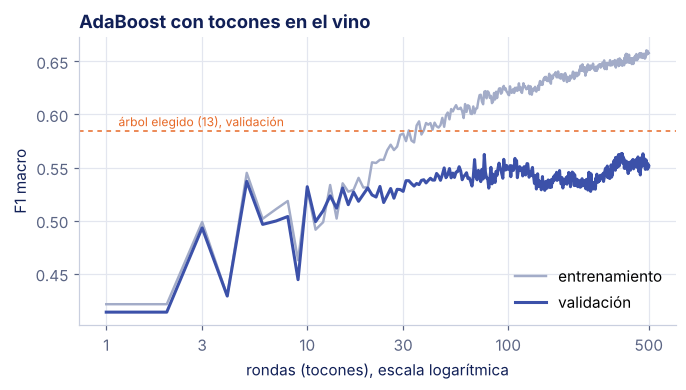

In [9]:
def curvas(crear, con_entrenamiento=True):
    # F1 macro después de cada ronda (staged_predict), promedio de los 5 pliegues: (entrenamiento, validación).
    entr, val = [], []
    for a, b in pliegues.split(X_e, y_e, g_e):
        m = crear().fit(X_e.iloc[a], y_e.iloc[a])
        if con_entrenamiento:
            entr.append([f1_score(y_e.iloc[a], p, average="macro") for p in m.staged_predict(X_e.iloc[a])])
        val.append([f1_score(y_e.iloc[b], p, average="macro") for p in m.staged_predict(X_e.iloc[b])])
    L = min(len(v) for v in val)
    return (np.mean([t[:L] for t in entr], axis=0) if entr else None), np.mean([v[:L] for v in val], axis=0)


inicio = time.perf_counter()
ada_entr, ada_val = curvas(lambda: AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=500, random_state=0))
print(f"{time.perf_counter() - inicio:.0f} s")
for r in [1, 10, 50, 100, 500]:
    print(f"Ronda {r:3d}: entrenamiento {ada_entr[r - 1]:.3f}, validación {ada_val[r - 1]:.3f}")
print(f"Mejor validación: {ada_val.max():.3f}, en la ronda {ada_val.argmax() + 1}")

fig, ax = plt.subplots(figsize=(7, 3.4))
rondas_x = np.arange(1, len(ada_val) + 1)
ax.plot(rondas_x, ada_entr, color="#A3ACC8", linewidth=1.6, label="entrenamiento")
ax.plot(rondas_x, ada_val, color=AZUL_MEDIO, linewidth=2, label="validación")
ax.axhline(0.584, color=NARANJA, linewidth=1, linestyle=(0, (3, 3)))
ax.text(1.15, 0.589, "árbol elegido (13), validación", color=NARANJA, fontsize=8)
ax.set_xscale("log")
ax.set_xticks([1, 3, 10, 30, 100, 500], ["1", "3", "10", "30", "100", "500"])
ax.tick_params(which="minor", length=0)
ax.set_xlabel("rondas (tocones), escala logarítmica")
ax.set_ylabel("F1 macro")
ax.set_title("AdaBoost con tocones en el vino")
ax.legend(loc="lower right")
plt.show()

**Lectura.** El F1 de validación pasa de 0.414 en la ronda 1 a 0.543 en la 50 y 0.551 en la 500; el de entrenamiento, de 0.421 a 0.658. Un tocón solo tiene dos hojas y nunca predice una de las tres clases; sumando tocones, boosting baja ese sesgo. Aun así, 500 tocones quedan por debajo del árbol elegido de la sesión 13 (0.584 en validación): cada tocón pregunta una sola variable, así que su suma es un modelo aditivo, sin interacciones entre variables. El mejor punto de la curva, 0.563 en la ronda 369, se eligió mirando la validación: es optimista (diapositiva 18).

### Tres clases: SAMME

Con $K$ clases, adivinar acierta $1/K$, y un modelo débil solo necesita $\varepsilon < 1 - 1/K$. SAMME (Zhu et al., 2009), que es lo que implementa `AdaBoostClassifier`, suma $\ln(K-1)$ al peso de cada modelo y repesa solo a los mal clasificados, multiplicándolos por $e^{\alpha_t}$ (diapositiva 19):

$$\alpha_t = \ln\frac{1-\varepsilon_t}{\varepsilon_t} + \ln(K-1)$$

Con $K = 2$ es el doble del $\alpha$ de la sección 1, que da el mismo clasificador. Lo comprobamos en el modelo entrenado con todo el entrenamiento:

In [10]:
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=500, random_state=0).fit(X_e, y_e)
e0 = ada.estimator_errors_[0]
print(f"Ronda 1: error ponderado {e0:.3f};  peso {ada.estimator_weights_[0]:.3f};  "
      f"ln({1 - e0:.3f}/{e0:.3f}) + ln 2 = {math.log((1 - e0) / e0) + math.log(2):.3f}")
resto = ada.estimator_errors_[1:]
print(f"Rondas 2 a 500: error ponderado de {resto.min():.3f} a {resto.max():.3f}, mediana {np.median(resto):.3f}; "
      f"pasa de ½ en {(resto > 0.5).sum()} de {len(resto)} rondas. Límite con 3 clases: ⅔ = {2 / 3:.3f}")

Ronda 1: error ponderado 0.410;  peso 1.058;  ln(0.590/0.410) + ln 2 = 1.058
Rondas 2 a 500: error ponderado de 0.492 a 0.663, mediana 0.648; pasa de ½ en 498 de 499 rondas. Límite con 3 clases: ⅔ = 0.667


**Lectura.** En la ronda 1, el tocón se equivoca en 41.0 % del peso y SAMME le da $\alpha = \ln(0.590/0.410) + \ln 2 = 1.058$. Desde la ronda 2, los errores ponderados van de 0.492 a 0.663, con mediana 0.648: casi todos pasan de ½, y un AdaBoost de dos clases se habría detenido en la ronda 2. SAMME sigue mientras el error quede por debajo de ⅔, el límite que importa con tres clases.

En scikit-learn, el modelo base se pasa con `estimator`. El notebook de la sesión 17 de 2024 usaba `base_estimator`, que se renombró en la versión 1.2 y ya no existe; desde la 1.6, `AdaBoostClassifier` solo implementa SAMME.

### ¿Y con árboles más profundos?

Boosting pide modelos débiles: con sesgo alto y varianza baja (diapositiva 7). ¿Qué pasa si le damos árboles más profundos? Tarda alrededor de un minuto.

In [11]:
inicio = time.perf_counter()
filas = {}
for nombre, d in [("tocón", 1), ("profundidad 2", 2), ("profundidad 3", 3), ("profundidad 6", 6), ("sin límite", None)]:
    m = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=d, random_state=0), n_estimators=500, random_state=0)
    filas[nombre] = evaluar(m)
    filas[nombre]["rondas"] = len(m.estimators_)            # m quedó entrenado con todo el entrenamiento
    filas[nombre]["error ronda 1"] = m.estimator_errors_[0]
print(f"{time.perf_counter() - inicio:.0f} s")
profundidad = pd.DataFrame(filas).T.drop(columns="segundos de la validación")
profundidad["rondas"] = profundidad["rondas"].astype(int)
profundidad.round(3)

54 s


,"F1 macro, validación",desv. est.,"F1 macro, entrenamiento","F1 macro, prueba",rondas,error ronda 1
tocón,0.551,0.032,0.658,0.550,500,0.410
profundidad 2,0.572,0.033,0.837,0.578,500,0.410
profundidad 3,0.567,0.021,0.918,0.571,500,0.364
profundidad 6,0.573,0.035,1.000,0.637,500,0.249
sin límite,0.558,0.031,1.000,0.490,1,0.000


**Lectura.** Con árboles de profundidad 2, AdaBoost llega a 0.572 en validación y 0.578 en prueba; con 3, a 0.567 y 0.571; con 6, a 0.573 y 0.637, con el entrenamiento en 1.000. El F1 de entrenamiento sube con la profundidad y el de validación apenas se mueve. Con árboles sin límite pasa algo distinto: el primer árbol no se equivoca en el entrenamiento, $\varepsilon = 0$, su $\alpha$ sería infinito y scikit-learn se detiene con ese único árbol. Queda un árbol completo, como el de ayer (0.558 en validación y 0.490 en prueba, contra 0.551 y 0.484): boosting no tiene nada que corregir.

---

## 3. Gradient boosting a mano: los 14 días

Gradient boosting (Friedman, 2001; diapositivas 21 a 24) construye una función $F(x)$, la suma de los árboles, y en cada ronda ajusta un árbol de regresión al **gradiente negativo** de la pérdida. Con dos clases y log-loss, $F$ es el logaritmo de los momios de la clase positiva, $p = 1/(1 + e^{-F})$, y el gradiente negativo es el residuo $y - p$.

1. Se empieza con la constante que minimiza la pérdida. Con log-loss es el logaritmo de los momios: $F_0 = \ln\frac{9}{5}$, porque 9 de los 14 días se jugó.
2. Los pseudo-residuos son $r_i = y_i - p_0$, con $y_i \in \{0, 1\}$.
3. Un árbol de regresión se ajusta a los residuos.
4. Cada hoja recibe un paso de Newton, $w = \dfrac{\sum_i (y_i - p_i)}{\sum_i p_i(1-p_i)}$, y $F_1(x) = F_0 + \eta\, w(x)$, con la tasa de aprendizaje $\eta$.

Los atributos van en one-hot: el árbol de regresión de scikit-learn hace cortes binarios.

In [12]:
from sklearn.ensemble import GradientBoostingClassifier

y01 = nominal.Play.astype(int).to_numpy()
F0 = math.log(y01.sum() / (len(y01) - y01.sum()))
p0 = 1 / (1 + math.exp(-F0))
r0 = y01 - p0
print(f"F0 = ln(9/5) = {F0:.3f};  p0 = 9/14 = {p0:.3f}")
print(f"Pseudo-residuos: {1 - p0:.3f} en los días Sí y {-p0:.3f} en los No; suman {abs(r0.sum()):.0f}")

X_dias = pd.get_dummies(nominal[ATRIBUTOS], dtype=float)    # una columna por valor: overcast, sunny, high…
mejora = {}
for col in X_dias.columns:
    izq = X_dias[col].to_numpy() == 1
    sse = lambda r: ((r - r.mean()) ** 2).sum()
    mejora[col] = sse(r0) - sse(r0[izq]) - sse(r0[~izq])    # cuánto baja el error cuadrático de los residuos
print("\nLos mejores cortes para un tocón de regresión:")
print(pd.Series(mejora).sort_values(ascending=False).head(5).round(3).to_string())

F0 = ln(9/5) = 0.588;  p0 = 9/14 = 0.643
Pseudo-residuos: 0.357 en los días Sí y -0.643 en los No; suman 0

Los mejores cortes para un tocón de regresión:
Outlook_overcast    0.714
Humidity_normal     0.643
Humidity_high       0.643
Outlook_sunny       0.459
Wind_weak           0.214


In [13]:
def hoja(en_hoja, p):
    return (y01[en_hoja] - p[en_hoja]).sum() / (p[en_hoja] * (1 - p[en_hoja])).sum()


p_0 = np.full(14, p0)
over = X_dias["Outlook_overcast"].to_numpy() == 1
w_over, w_resto = hoja(over, p_0), hoja(~over, p_0)
print(f"Hoja overcast: 4({1 - p0:.3f}) / 4({p0 * (1 - p0):.3f}) = {w_over:.3f}")
print(f"Hoja resto:    [5({1 - p0:.3f}) − 5({p0:.3f})] / 10({p0 * (1 - p0):.3f}) = {w_resto:.3f}")
eta = 0.1
for nombre, w_h in [("overcast", w_over), ("resto", w_resto)]:
    F1 = F0 + eta * w_h
    print(f"{nombre}: F1 = {F0:.3f} + {eta}({w_h:.3f}) = {F1:.3f};  p = {1 / (1 + math.exp(-F1)):.3f}")

gb = GradientBoostingClassifier(n_estimators=1, max_depth=1, learning_rate=eta, random_state=0).fit(X_dias, nominal.Play)
arbol = gb.estimators_[0, 0].tree_
print(f"\nscikit-learn: corte en {X_dias.columns[arbol.feature[0]]}; hojas {arbol.value[1:, 0, 0].round(3).tolist()}; "
      f"F1 = {np.unique(gb.decision_function(X_dias).round(3)).tolist()}; p = {np.unique(gb.predict_proba(X_dias)[:, 1].round(3)).tolist()}")

Hoja overcast: 4(0.357) / 4(0.230) = 1.556
Hoja resto:    [5(0.357) − 5(0.643)] / 10(0.230) = -0.622
overcast: F1 = 0.588 + 0.1(1.556) = 0.743;  p = 0.678
resto: F1 = 0.588 + 0.1(-0.622) = 0.526;  p = 0.628

scikit-learn: corte en Outlook_overcast; hojas [-0.622, 1.556]; F1 = [0.526, 0.743]; p = [0.628, 0.678]


**Lectura.** $F_0 = \ln(9/5) = 0.588$ y $p_0 = 9/14 = 0.643$: los pseudo-residuos son 0.357 en los 9 días Sí y −0.643 en los 5 No, y suman cero, porque $F_0$ ya es el mejor modelo constante. El mejor corte para un tocón de regresión separa overcast (4 días, todos Sí) de los otros 10 (5 Sí y 5 No): reduce el error cuadrático de los residuos en 0.714, contra 0.643 de Humidity y 0.459 de sunny. Las hojas valen $4(0.357)/4(0.230) = 1.556$ y $[5(0.357) - 5(0.643)]/10(0.230) = -0.622$. Con $\eta = 0.1$, $F_1$ es 0.743 en overcast ($p = 0.678$) y 0.526 en el resto ($p = 0.628$): cada hoja se acerca un poco a su proporción real, 4 de 4 y 5 de 10.

`GradientBoostingClassifier` da exactamente lo mismo: el mismo corte, las mismas hojas y las mismas probabilidades (diapositiva 25). La diapositiva 24 corrige al deck original: al inicio, los pseudo-residuos son $y - p_0$, no las observaciones.

---

## 4. XGBoost a mano: la ganancia con $\lambda$

XGBoost (Chen y Guestrin, 2016) usa, para cada ejemplo, el gradiente $g_i$ y la curvatura $h_i$ de la pérdida respecto a $F$. Con log-loss, $g_i = p_i - y_i$ y $h_i = p_i(1-p_i)$. Con $G$ y $H$ sumados sobre los ejemplos de una hoja, el valor óptimo de la hoja y la mejora de un corte son (diapositiva 30):

$$w^* = -\frac{G}{H+\lambda} \qquad \mathrm{Ganancia} = \frac{1}{2}\left[\frac{G_L^2}{H_L+\lambda} + \frac{G_R^2}{H_R+\lambda} - \frac{(G_L+G_R)^2}{H_L+H_R+\lambda}\right] - \gamma$$

$\lambda$ (`reg_lambda`, 1 por omisión) castiga los valores grandes en las hojas, y $\gamma$ (`gamma`, 0 por omisión) es lo que debe ganar un corte para hacerse. Con $\lambda = 0$, $w^*$ es el paso de Newton de la sección 3.

In [14]:
g = p0 - y01                       # gradiente de la log-loss respecto a F, en F0
h = np.full(14, p0 * (1 - p0))     # curvatura


def corte(col, lam):
    m = X_dias[col].to_numpy() == 1
    GL, HL, GR, HR = g[m].sum(), h[m].sum(), g[~m].sum(), h[~m].sum()
    gan = 0.5 * (GL**2 / (HL + lam) + GR**2 / (HR + lam) - (GL + GR)**2 / (HL + HR + lam))
    return {"H de la hoja": HL, "ganancia": gan, "hoja": -GL / (HL + lam), "resto": -GR / (HR + lam)}


cortes = pd.DataFrame({(col, lam): corte(col, lam) for lam in (0, 1)
                       for col in ["Outlook_overcast", "Humidity_normal", "Outlook_sunny", "Wind_weak"]}).T
cortes.index.names = ["corte", "λ"]
cortes.sort_index(level="λ").round(3)

,,H de la hoja,ganancia,hoja,resto
corte,λ,,,,
Humidity_normal,0,1.607,1.400,0.933,-0.933
Outlook_overcast,0,0.918,1.556,1.556,-0.622
Outlook_sunny,0,1.148,0.999,-1.058,0.588
Wind_weak,0,1.837,0.467,0.467,-0.622
Humidity_normal,1,1.607,0.863,0.575,-0.575
Outlook_overcast,1,0.918,0.842,0.745,-0.433
Outlook_sunny,1,1.148,0.584,-0.565,0.396
Wind_weak,1,1.837,0.284,0.302,-0.361


In [15]:
import xgboost as xgb

for lam, mcw in [(0, 0), (1, 0), (0, 1)]:
    m = xgb.XGBClassifier(n_estimators=1, max_depth=1, learning_rate=1.0, base_score=9 / 14, reg_lambda=lam,
                          min_child_weight=mcw, tree_method="exact", random_state=0).fit(X_dias, y01)
    t = m.get_booster().trees_to_dataframe()
    raiz, hojas = t.iloc[0], t.iloc[1:]
    print(f"λ = {lam}, min_child_weight = {mcw}: corte en {raiz.Feature}; ganancia que reporta XGBoost {raiz.Gain:.3f} "
          f"= 2 × {raiz.Gain / 2:.3f}; hojas {hojas.Gain.round(3).tolist()}")

λ = 0, min_child_weight = 0: corte en Outlook_overcast; ganancia que reporta XGBoost 3.111 = 2 × 1.556; hojas [-0.622, 1.556]


λ = 1, min_child_weight = 0: corte en Humidity_high; ganancia que reporta XGBoost 1.726 = 2 × 0.863; hojas [0.575, -0.575]


λ = 0, min_child_weight = 1: corte en Humidity_high; ganancia que reporta XGBoost 2.800 = 2 × 1.400; hojas [0.933, -0.933]


**Lectura.** Con $\lambda = 0$ gana overcast, con ganancia 1.556, y sus hojas son exactamente las de la sección 3: 1.556 y −0.622. Con $\lambda = 1$, el valor por omisión, gana Humidity: 0.863 contra 0.842. La hoja de overcast tiene poca curvatura, $H = 4(0.230) = 0.918$, y $\lambda = 1$ casi la duplica en el denominador: su valor baja de 1.556 a 0.745. XGBoost reporta 3.111 y 1.726: el doble, porque no multiplica por ½. Y con `min_child_weight = 1`, que también es el valor por omisión, una hoja necesita $H \geq 1$: la de overcast ni siquiera se permite, y con $\lambda = 0$ gana Humidity con 1.4 (reportado, 2.8).

Las dos regularizaciones frenan a las hojas con pocos ejemplos o con ejemplos muy seguros, que es donde el árbol sobreajusta.

---

## 5. Tasa de aprendizaje y parada temprana

### La tasa de aprendizaje

`GradientBoostingClassifier` en el vino con cuatro tasas de aprendizaje $\eta$, 600 rondas y árboles de profundidad 3, su valor por omisión. Trazamos el F1 macro de validación después de cada ronda. Tarda un par de minutos.

In [16]:
inicio = time.perf_counter()
curvas_gb = {}
for eta in [1.0, 0.3, 0.1, 0.03]:
    _, curvas_gb[eta] = curvas(lambda eta=eta: GradientBoostingClassifier(learning_rate=eta, n_estimators=600, random_state=0),
                              con_entrenamiento=False)
print(f"{time.perf_counter() - inicio:.0f} s")
tasas = pd.DataFrame({f"η = {eta:g}": {"mejor F1 de validación": v.max(), "en la ronda": v.argmax() + 1,
                                        "F1 en la ronda 100": v[99], "F1 en la ronda 600": v[-1]}
                      for eta, v in curvas_gb.items()}).T
tasas["en la ronda"] = tasas["en la ronda"].astype(int)
tasas.round(3)

116 s


,mejor F1 de validación,en la ronda,F1 en la ronda 100,F1 en la ronda 600
η = 1,0.582,3,0.561,0.533
η = 0.3,0.587,7,0.563,0.566
η = 0.1,0.597,36,0.581,0.560
η = 0.03,0.591,103,0.588,0.569


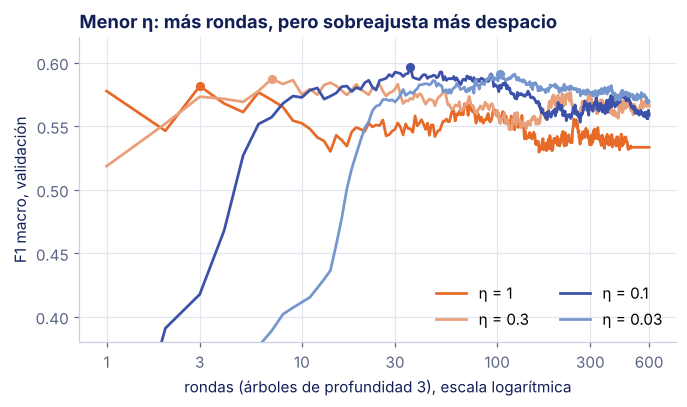

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.6))
colores = {1.0: NARANJA, 0.3: "#E9A07A", 0.1: AZUL_MEDIO, 0.03: AZUL}
for eta, v in curvas_gb.items():
    x = np.arange(1, len(v) + 1)
    ax.plot(x, v, color=colores[eta], linewidth=1.8, label=f"η = {eta:g}")
    ax.plot(v.argmax() + 1, v.max(), "o", color=colores[eta], markersize=5)
ax.set_xscale("log")
ax.set_xticks([1, 3, 10, 30, 100, 300, 600], ["1", "3", "10", "30", "100", "300", "600"])
ax.tick_params(which="minor", length=0)
ax.set_ylim(0.38, 0.62)
ax.set_xlabel("rondas (árboles de profundidad 3), escala logarítmica")
ax.set_ylabel("F1 macro, validación")
ax.set_title("Menor η: más rondas, pero sobreajusta más despacio")
ax.legend(loc="lower right", ncol=2)
plt.show()

**Lectura.** Con $\eta = 1$, el mejor F1 de validación, 0.582, llega en la ronda 3, y en la 600 ya cayó a 0.533. Con $\eta = 0.3$, 0.587 en la ronda 7. Con $\eta = 0.1$, 0.597 en la ronda 36; con las 100 rondas por omisión de scikit-learn, 0.581. Con $\eta = 0.03$, 0.591 en la ronda 103. Menor $\eta$ pide más rondas, pero sobreajusta más despacio, y el máximo es más ancho. Los máximos se eligieron mirando la validación, así que son optimistas; para elegir el número de rondas sin mirarla está la **parada temprana** (diapositiva 27).

### La parada temprana, con grupos

La parada temprana aparta una parte del entrenamiento, mira la pérdida en ella después de cada ronda y se detiene cuando deja de mejorar. `HistGradientBoostingClassifier` la trae: con `early_stopping=True` aparta 10 % al azar (estratificado, pero sin grupos), y se detiene cuando 10 rondas seguidas no mejoran la log-loss. Por omisión solo la activa con más de 10 000 ejemplos; aquí la pedimos.

Con las gemelas del vino, ese 10 % al azar tiene la misma trampa que la validación sin agrupar: muchas gemelas de los vinos apartados se quedan en el entrenamiento. La comparamos con una partición **agrupada** dentro del entrenamiento de cada pliegue: 20 % de los grupos para elegir la ronda con menor log-loss, y después el modelo con esas rondas y todo el entrenamiento del pliegue. En los dos casos, $\eta = 0.05$.

In [18]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import log_loss

parada = {"interna, 10 % al azar": [], "agrupada, 20 % de los grupos": []}
inicio = time.perf_counter()
for a, b in pliegues.split(X_e, y_e, g_e):
    X_a, y_a, g_a = X_e.iloc[a], y_e.iloc[a], g_e.iloc[a]
    m = HistGradientBoostingClassifier(early_stopping=True, max_iter=2000, learning_rate=0.05, random_state=0).fit(X_a, y_a)
    parada["interna, 10 % al azar"].append((m.n_iter_, -m.validation_score_.max(),
                                            f1_score(y_e.iloc[b], m.predict(X_e.iloc[b]), average="macro")))
    i_a, i_v = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(X_a, y_a, g_a))
    m = HistGradientBoostingClassifier(early_stopping=False, max_iter=2000, learning_rate=0.05, random_state=0)
    m.fit(X_a.iloc[i_a], y_a.iloc[i_a])
    perdidas = [log_loss(y_a.iloc[i_v], P, labels=m.classes_) for P in m.staged_predict_proba(X_a.iloc[i_v])]
    mejor = int(np.argmin(perdidas)) + 1
    m = HistGradientBoostingClassifier(early_stopping=False, max_iter=mejor, learning_rate=0.05, random_state=0).fit(X_a, y_a)
    parada["agrupada, 20 % de los grupos"].append((mejor, min(perdidas), f1_score(y_e.iloc[b], m.predict(X_e.iloc[b]), average="macro")))
print(f"{time.perf_counter() - inicio:.0f} s")
resumen = pd.DataFrame({nombre: {"rondas, promedio": np.mean([r[0] for r in v]), "log-loss de la parada": np.mean([r[1] for r in v]),
                                 "F1 macro, validación": np.mean([r[2] for r in v]), "desv. est.": np.std([r[2] for r in v])}
                        for nombre, v in parada.items()}).T.round(3)
resumen.insert(0, "rondas en cada pliegue", [[int(r[0]) for r in v] for v in parada.values()])
resumen

43 s


,rondas en cada pliegue,"rondas, promedio",log-loss de la parada,"F1 macro, validación",desv. est.
"interna, 10 % al azar","[74, 60, 37, 70, 50]",58.2,0.614,0.572,0.047
"agrupada, 20 % de los grupos","[17, 33, 19, 13, 38]",24.0,0.798,0.575,0.025


**Lectura.** La parada interna se detiene en 74, 60, 37, 70 y 50 rondas (58 en promedio) y su 10 % apartado promete una log-loss de 0.614. La agrupada elige 17, 33, 19, 13 y 38 rondas (24 en promedio) y mide una log-loss de 0.798. La interna es optimista por las gemelas: cree que el modelo sigue mejorando cuando ya empezó a memorizar. En el F1 de validación casi no se nota (0.572 contra 0.575), pero el número de rondas y la pérdida que se reportan no son de fiar. Es la misma lección del OOB de ayer: cualquier validación interna, la del bosque o la de la parada temprana, tiene que respetar los grupos.

---

## 6. Las bibliotecas y la tabla de la unidad 5

### XGBoost, LightGBM y CatBoost

Las bibliotecas de gradient boosting más usadas, con sus valores por omisión (diapositiva 31). XGBoost pide las clases como números; LightGBM y CatBoost aceptan las etiquetas tal cual. A CatBoost le pedimos que no escriba archivos (`allow_writing_files=False`); si no, deja una carpeta `catboost_info`. Los segundos son los de la validación cruzada completa y cambian con cada computadora. Tarda alrededor de medio minuto.

In [19]:
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

bibliotecas = {
    "AdaBoost, 500 tocones": (AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=500, random_state=0), False),
    "GradientBoosting": (GradientBoostingClassifier(random_state=0), False),
    "HistGradientBoosting": (HistGradientBoostingClassifier(random_state=0), False),
    "XGBoost": (XGBClassifier(random_state=0), True),
    "LightGBM": (LGBMClassifier(random_state=0, verbose=-1), False),
    "CatBoost": (CatBoostClassifier(random_seed=0, verbose=0, allow_writing_files=False), False),
}
inicio = time.perf_counter()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")          # CatBoost devuelve sus predicciones como columna; scikit-learn lo avisa
    tabla_boosting = pd.DataFrame({nombre: evaluar(m, numericas) for nombre, (m, numericas) in bibliotecas.items()}).T
print(f"{time.perf_counter() - inicio:.0f} s")
tabla_boosting.round(3)

28 s


,"F1 macro, validación",desv. est.,"F1 macro, entrenamiento","F1 macro, prueba",segundos de la validación
"AdaBoost, 500 tocones",0.551,0.032,0.658,0.550,8.030
GradientBoosting,0.581,0.025,0.907,0.610,3.865
HistGradientBoosting,0.577,0.044,1.000,0.630,2.595
XGBoost,0.579,0.032,1.000,0.592,1.007
LightGBM,0.574,0.041,1.000,0.598,1.380
CatBoost,0.575,0.019,1.000,0.639,7.041


**Lectura.** Con valores por omisión, las cinco implementaciones de gradient boosting empatan en validación: de 0.574 (LightGBM) a 0.581 (GradientBoosting), con desviaciones de 0.02 a 0.04 entre pliegues. En prueba van de 0.592 (XGBoost) a 0.639 (CatBoost): diferencias del tamaño de esa variación. Todas, menos GradientBoosting, llegan a 1.000 en entrenamiento. AdaBoost con tocones queda atrás, en 0.551.

Con 1279 vinos, todas tardan unos segundos. La diferencia de velocidad aparece con decenas de miles de filas: ahí los histogramas de HistGradientBoosting, LightGBM y XGBoost (que los usa por omisión desde su versión 2.0) son mucho más rápidos que los cortes exactos de GradientBoosting.

### La unidad 5 en el vino

La tabla de ayer (notebook 17, sección 6) con el boosting de hoy. Las cifras de ayer se copian tal cual: mismo protocolo, mismas particiones. Agregamos el tocón solo, que es el punto de partida de AdaBoost.

In [20]:
jueves = pd.DataFrame({
    "regresión logística (11)": (0.562, 0.022, 0.573),
    "árbol elegido (13)": (0.584, 0.022, 0.551),
    "Naive Bayes (14)": (0.579, 0.044, 0.596),
    "kNN (15)": (0.566, 0.041, 0.584),
    "SVM (16)": (0.582, 0.027, 0.576),
    "árbol completo": (0.551, 0.038, 0.484),
    "bagging, 500 árboles": (0.592, 0.039, 0.618),
    "random forest, 500 árboles": (0.592, 0.043, 0.621),
    "Extra-Trees, 500 árboles": (0.573, 0.053, 0.642),
    "votación dura (los 5)": (0.588, 0.022, 0.595),
    "votación suave (los 5)": (0.591, 0.013, 0.572),
    "stacking, fuera del pliegue": (0.560, 0.019, 0.573),
}, index=["F1 macro, validación", "desv. est.", "F1 macro, prueba"]).T

columnas = ["F1 macro, validación", "desv. est.", "F1 macro, prueba"]
tocon_solo = pd.DataFrame({"tocón": evaluar(DecisionTreeClassifier(max_depth=1, random_state=0))}).T[columnas]
unidad5 = pd.concat([jueves, tocon_solo, tabla_boosting[columnas]])
unidad5.round(3)

,"F1 macro, validación",desv. est.,"F1 macro, prueba"
regresión logística (11),0.562,0.022,0.573
árbol elegido (13),0.584,0.022,0.551
Naive Bayes (14),0.579,0.044,0.596
kNN (15),0.566,0.041,0.584
SVM (16),0.582,0.027,0.576
árbol completo,0.551,0.038,0.484
"bagging, 500 árboles",0.592,0.039,0.618
"random forest, 500 árboles",0.592,0.043,0.621
"Extra-Trees, 500 árboles",0.573,0.053,0.642
votación dura (los 5),0.588,0.022,0.595


**Lectura.** Cada ensamble arregla a su modelo base: bagging y random forest al árbol completo (de 0.484 a 0.62 en prueba), y boosting al tocón (de 0.389 a entre 0.55 y 0.64). En validación nadie se separa: todos los ensambles quedan entre 0.55 y 0.59, con desviaciones de 0.01 a 0.05 entre pliegues, y el mejor de la unidad 4, el árbol elegido, está en 0.584. Con estas 11 variables y 1279 vinos, los modelos de la unidad 4 parecen estar ya cerca de lo que se puede predecir. En la Práctica 4 lo comprobarán con la deserción escolar, que tiene más ejemplos y más variables (diapositiva 36).

### ¿Qué gana a gran escala?

Un conjunto de datos no basta para ordenar modelos. **TabArena** (Erickson et al., 2025) es un benchmark vivo, con tabla de posiciones pública en [tabarena.ai](https://tabarena.ai): 51 conjuntos de datos curados de 1053 candidatos, de 500 a 250 000 filas, y 16 modelos (diapositiva 33). Sus conclusiones:

- Los árboles con gradient boosting siguen entre los mejores: con ajuste de hiperparámetros, gana CatBoost.
- Las redes neuronales los alcanzan con más tiempo de cómputo y ensamble de configuraciones; con ajuste y ensamble, TabM, LightGBM y RealMLP quedan arriba.
- Los modelos fundacionales, como TabPFNv2 y TabICL, destacan en los conjuntos chicos.
- El método de validación y el ensamble de configuraciones pesan mucho en el resultado, y un ensamble de todos los modelos supera a cada uno.

**TabPFN** (Hollmann et al., 2025) es uno de esos modelos fundacionales: un *transformer* preentrenado con millones de tablas sintéticas, que con una tabla nueva no se entrena, sino que recibe juntos el entrenamiento y la prueba y predice en una pasada. Es «meta-aprendizaje» en el sentido de la literatura (diapositiva 64 del jueves). Lo veremos en la sesión 25, con los *transformers* (diapositiva 34).

---

### Declaración de uso de IA generativa

Este notebook fue elaborado con apoyo de Claude (Anthropic) para estructurar el contenido a partir de las diapositivas de la sesión, redactar el texto explicativo y preparar los ejemplos. El diseño pedagógico, la selección de temas y la revisión final son responsabilidad del titular del curso.

### Referencias

- Freund, Y., & Schapire, R. E. (1997). A decision-theoretic generalization of on-line learning and an application to boosting. *Journal of Computer and System Sciences*, 55(1), 119-139.
- Friedman, J., Hastie, T., & Tibshirani, R. (2000). Additive logistic regression: a statistical view of boosting. *Annals of Statistics*, 28(2), 337-407.
- Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics*, 29(5), 1189-1232.
- Zhu, J., Zou, H., Rosset, S., & Hastie, T. (2009). Multi-class AdaBoost. *Statistics and Its Interface*, 2(3), 349-360.
- Chen, T., & Guestrin, C. (2016). XGBoost: a scalable tree boosting system. En *KDD 2016*, 785-794.
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: a highly efficient gradient boosting decision tree. En *NeurIPS 30*.
- Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., & Gulin, A. (2018). CatBoost: unbiased boosting with categorical features. En *NeurIPS 31*.
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning*, 2a ed., capítulo 10: Boosting and Additive Trees. Springer.
- Russell, S., & Norvig, P. (2010). *Artificial Intelligence: A Modern Approach*, 3a ed., sección 18.10: Ensemble Learning. Prentice Hall.
- Rocca, J. (2019). Ensemble methods: bagging, boosting and stacking. *Towards Data Science*.
- Erickson, N., et al. (2025). TabArena: a living benchmark for machine learning on tabular data. *NeurIPS 2025, Datasets and Benchmarks Track*. [arXiv:2506.16791](https://arxiv.org/abs/2506.16791)
- Hollmann, N., et al. (2025). Accurate predictions on small data with a tabular foundation model. *Nature*, 637, 319-326. [doi:10.1038/s41586-024-08328-6](https://doi.org/10.1038/s41586-024-08328-6)
- Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *NeurIPS 2022, Datasets and Benchmarks Track*. [arXiv:2207.08815](https://arxiv.org/abs/2207.08815)
- Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). Modeling wine preferences by data mining from physicochemical properties. *Decision Support Systems*, 47(4), 547-553.
- [scikit-learn: Gradient-boosted trees](https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosted-trees) · [AdaBoost](https://scikit-learn.org/stable/modules/ensemble.html#adaboost) · [HistGradientBoostingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html) · [XGBoost](https://xgboost.readthedocs.io/) · [LightGBM](https://lightgbm.readthedocs.io/) · [CatBoost](https://catboost.ai/docs/)